# P05 — Анализ ошибок / Error analysis
Практика в Colab CPU, 60–90 минут. Выполняйте по порядку. / Colab CPU practice, 60–90 minutes. Run in order.

**Реальные данные / Real data:** [Digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), [UCI source](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits). Одно наблюдение — изображение рукописной цифры 8×8; признаки — 64 яркости 0–16, доступные при получении изображения; цель — цифра 0–9. Это не MNIST. / One observation is an 8×8 handwritten digit; features are 64 intensities, available when the image arrives; target is the digit 0–9. This is not MNIST.

Разбиение по изображениям, стратифицированное 60/20/20. В загрузчике нет ID автора: нельзя утверждать перенос на новых авторов. Исходный sklearn-набор — копия тестовой части UCI; здесь это отдельный учебный эксперимент, не официальный UCI benchmark. / Stratified image split, approximately 60/20/20. Writer IDs are unavailable, so this does not establish generalization to unseen writers. sklearn contains the original UCI test portion; our resplit is a teaching experiment, not the official benchmark.

In [1]:
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
SEED = 42

In [2]:
data = load_digits()
X, y = data.data / 16., data.target
# Fixed physical scale, no statistics fitted on validation/test.
labels = np.arange(10)
ids = np.arange(len(y))
trainval, test = train_test_split(ids, test_size=.2, random_state=SEED, stratify=y)
train, val = train_test_split(trainval, test_size=.25, random_state=SEED, stratify=y[trainval])
assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
assert sorted(np.r_[train,val,test]) == ids.tolist()
print({k: len(v) for k,v in {'train':train,'validation':val,'test':test}.items()})

{'train': 1077, 'validation': 360, 'test': 360}


## 1. Baseline и диагностика / Baseline and diagnosis
Фиксируем 1-NN до просмотра validation. Считаем Train и Validation одинаковой метрикой macro-F1. / Fix 1-NN before inspecting validation. Compare train and validation using the same macro-F1 metric.

Train macro-F1: 1.0
Validation macro-F1: 0.9889385227775321


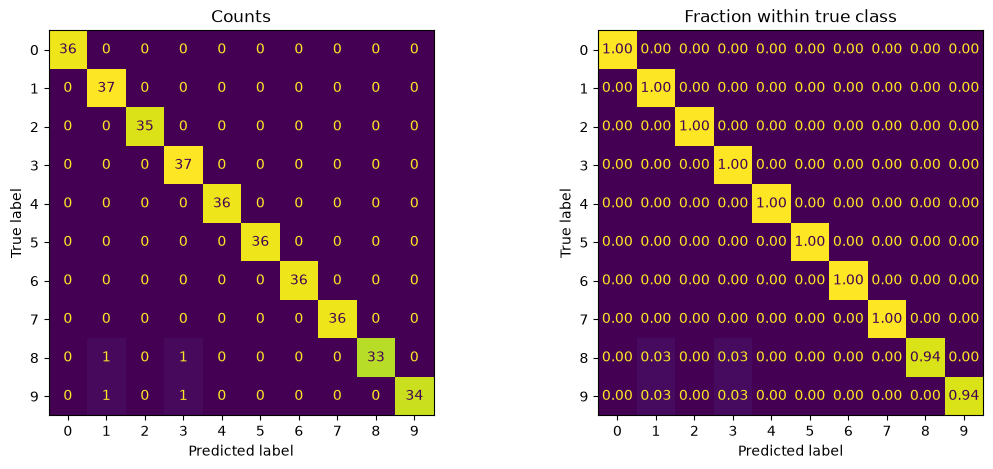

,digit,support,recall
0,0,36,1.000000
1,1,37,1.000000
2,2,35,1.000000
3,3,37,1.000000
4,4,36,1.000000
5,5,36,1.000000
6,6,36,1.000000
7,7,36,1.000000
8,8,35,0.942857
9,9,36,0.944444


In [3]:
baseline = KNeighborsClassifier(n_neighbors=1).fit(X[train], y[train])
pred_train = baseline.predict(X[train]); pred_val = baseline.predict(X[val])
print('Train macro-F1:',f1_score(y[train],pred_train,average='macro'))
print('Validation macro-F1:',f1_score(y[val],pred_val,average='macro'))
cm = confusion_matrix(y[val],pred_val,labels=labels)
fig, ax = plt.subplots(1,2,figsize=(13,5))
ConfusionMatrixDisplay(cm,display_labels=labels).plot(ax=ax[0],colorbar=False)
row_cm = np.divide(cm,cm.sum(axis=1,keepdims=True),out=np.zeros_like(cm,dtype=float),where=cm.sum(axis=1,keepdims=True)>0)
ConfusionMatrixDisplay(row_cm,display_labels=labels).plot(ax=ax[1],values_format='.2f',colorbar=False)
ax[0].set_title('Counts');ax[1].set_title('Fraction within true class');plt.show()
support=cm.sum(axis=1)
recall=np.divide(np.diag(cm),support,out=np.zeros(10),where=support>0)
display(pd.DataFrame({'digit':labels,'support':support,'recall':recall}))

**Задание 1 / Exercise 1.** Найдите худший recall и самую частую направленную ошибку вне диагонали. Укажите числа и знаменатели. Почему Train=1 у 1-NN не доказывает отсутствие проблем? / Find the lowest recall and the most frequent directed off-diagonal error. Include counts and denominators. Why does training score 1 for 1-NN not prove good generalization?

Most frequent error: 8 -> 1 count 1


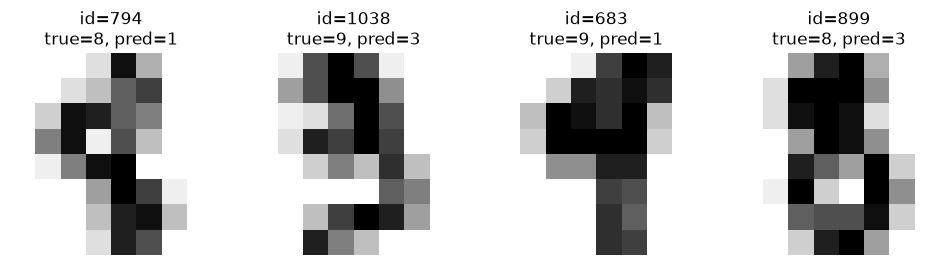

In [4]:
off = cm.copy(); np.fill_diagonal(off,0)
if off.max():
    true_digit, predicted_digit = np.unravel_index(off.argmax(),off.shape)
    print('Most frequent error:',true_digit,'->',predicted_digit,'count',off.max())
wrong = np.flatnonzero(y[val] != pred_val)
if not len(wrong): print('No validation errors / Ошибок validation нет')
else:
    fig, axes=plt.subplots(1,min(6,len(wrong)),figsize=(12,3),squeeze=False)
    for ax,pos in zip(axes.ravel(),wrong[:6]):
        ax.imshow(data.images[val[pos]],cmap='gray_r');ax.set_title(f'id={val[pos]}\ntrue={y[val[pos]]}, pred={pred_val[pos]}');ax.axis('off')
    plt.show()

**Задание 2 / Exercise 2.** Для трёх показанных ошибок запишите ID, истинную цифру, предсказание, наблюдаемый визуальный признак и гипотезу причины. Разделяйте наблюдение и догадку. Не объявляйте метку ошибочной без проверки. / For three displayed mistakes, record ID, true digit, prediction, visible feature and a possible cause. Distinguish observation from speculation; do not relabel without verification.

In [5]:
# Answer / Ответ: fill in your observations; no fabricated examples.
error_notes = []

## 2. Срезы / Slices
Заранее выбранный признак среза — средняя яркость изображения. Порог — медиана только Train. Это описательные срезы, не доказанные причины ошибок. / Prespecified slice feature: mean image intensity. Threshold: training median only. Slices are descriptive, not proven error causes.

In [6]:
intensity=X.mean(axis=1);cut=float(np.median(intensity[train]))
slices={'low_intensity':intensity[val]<=cut,'high_intensity':intensity[val]>cut}
rows=[]
for name,mask in slices.items():
    count=int(mask.sum());errors=int(np.sum(y[val][mask]!=pred_val[mask]))
    rows.append({'slice':name,'n':count,'errors':errors,'error_rate':errors/count if count else np.nan})
display(pd.DataFrame(rows))

,slice,n,errors,error_rate
0,low_intensity,188,1,0.005319
1,high_intensity,172,3,0.017442


**Задание 3 / Exercise 3.** Сопоставьте число ошибок и их долю. Как изменится доля при ещё одной ошибке? Почему слабый срез не доказывает, что яркость причинно влияет на результат? / Compare error counts and rates. How much would one extra error change each rate? Why does a weak slice not establish a causal effect of brightness?

## 3. Одна гипотеза / One hypothesis
До следующей ячейки запишите прогноз: переход 1-NN → 5-NN может уменьшить влияние отдельных соседей, но может сгладить редкие формы. Меняется только k. Сохраняем train/val/test и метрику. При равном macro-F1 оставляем baseline. / Before the next cell, predict whether 1-NN → 5-NN will help. It may reduce dependence on one neighbor but blur rare shapes. Change only k; keep splits and metric fixed. On equal macro-F1, retain baseline.

In [7]:
hypothesis = 'TODO: your prediction and evidence / прогноз и основание'
candidate=KNeighborsClassifier(n_neighbors=5).fit(X[train],y[train])
pred_candidate=candidate.predict(X[val])
base_f1=float(f1_score(y[val],pred_val,average='macro'))
candidate_f1=float(f1_score(y[val],pred_candidate,average='macro'))
selected_name='candidate' if candidate_f1>base_f1 else 'baseline'
selected={'candidate':candidate,'baseline':baseline}[selected_name]
print({'baseline':base_f1,'candidate':candidate_f1,'selected':selected_name})
print('Fixed:',int(((pred_val!=y[val])&(pred_candidate==y[val])).sum()))
print('Regressed:',int(((pred_val==y[val])&(pred_candidate!=y[val])).sum()))

{'baseline': 0.9889385227775321, 'candidate': 0.9806742360486822, 'selected': 'baseline'}
Fixed: 1
Regressed: 4


**Задание 4 / Exercise 4.** Объясните результат без требования «обязательно улучшить». Сравните исправленные и новые ошибки, macro-F1 и слабый класс. Заморозьте выбор перед Test. / Explain the result without requiring improvement. Compare fixed and new errors, macro-F1 and the weak class. Freeze selection before Test.

## 4. Однократный финальный Test / One final test
Выполните после фиксации выбора. Не меняйте k и правило выбора после этой ячейки. / Run after freezing selection. Do not change k or the selection rule after this cell.

In [8]:
test_pred=selected.predict(X[test])
print('Selected model:',selected_name)
print('Final test macro-F1:',f1_score(y[test],test_pred,average='macro'))
print('Final test accuracy:',accuracy_score(y[test],test_pred))
print('Baseline test macro-F1:',f1_score(y[test],baseline.predict(X[test]),average='macro'))
print('Versions:',np.__version__,sklearn.__version__)
print('Data SHA256:',hashlib.sha256(data.data.tobytes()+y.tobytes()).hexdigest())

Selected model: baseline
Final test macro-F1: 0.985890641187982
Final test accuracy: 0.9861111111111112
Baseline test macro-F1: 0.985890641187982
Versions: 2.5.3 1.9.1
Data SHA256: f6d9e39f37dc45d327f6db33428ee58970ccceabb2535a5c179de35886b70443


**Итог / Reflection.** Назовите одну подтверждённую ошибку, одну непроверенную причину и следующий эксперимент. Новый поиск после Test требует нового независимого контроля. / State one observed mistake, one unverified cause and a next experiment. Further selection after inspecting Test needs a fresh independent evaluation.